# 06 · Loss functions: MSE, MAE, binary and categorical cross-entropy

**Lecture:** *Loss Functions in Neural Networks* (18-08-2026) · **Notes:** `../notes/06_loss_functions.md`

> A **loss function** tells a network **how wrong** its prediction is. Training adjusts the weights to make it smaller. Different problems need different losses, because "error" means different things for regression, binary and multi-class classification.

In this notebook you will:
1. Recompute every worked example of the lecture (MSE = 466.67, MAE = 20, BCE and CCE values).
2. **See** why MSE is sensitive to outliers and MAE isn't, by fitting a line to data with one outlier.
3. **See** why classification uses cross-entropy rather than MSE, by measuring the gradient on a confidently wrong prediction.
4. Show that categorical and **sparse** categorical cross-entropy are the same loss with different label formats, and learn PyTorch's version of each (plus the "logits vs probabilities" trap).

Runs in seconds.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(0)

## 1 · Regression losses

**MSE = (1/n) Σ (yᵢ − ŷᵢ)²**   **MAE = (1/n) Σ |yᵢ − ŷᵢ|**

The lecture's example: actual (100, 200, 300), predicted (90, 220, 270).

In [2]:
y = np.array([100, 200, 300]); y_hat = np.array([90, 220, 270])
err = y - y_hat
print("errors:", err, " squared:", err ** 2, " absolute:", np.abs(err))
print(f"MSE = ({' + '.join(map(str, err ** 2))}) / 3 = {np.mean(err ** 2):.2f}")
print(f"MAE = ({' + '.join(map(str, np.abs(err)))}) / 3 = {np.mean(np.abs(err)):.2f}")
print("PyTorch agrees:", F.mse_loss(torch.tensor(y_hat, dtype=torch.float), torch.tensor(y, dtype=torch.float)).item(),
      F.l1_loss(torch.tensor(y_hat, dtype=torch.float), torch.tensor(y, dtype=torch.float)).item())

errors: [ 10 -20  30]  squared: [100 400 900]  absolute: [10 20 30]
MSE = (100 + 400 + 900) / 3 = 466.67
MAE = (10 + 20 + 30) / 3 = 20.00
PyTorch agrees: 466.6666564941406 20.0


### Why squaring matters: errors of 2 and 10

In [3]:
for e in [2, 10, 100]:
    print(f"error {e:>3}: MSE contribution {e ** 2:>6}   MAE contribution {e:>3}")
print("an error 5x bigger counts 25x more under MSE, but only 5x more under MAE")
errors = np.array([2, 3, 4, 2, 3, 100])
print(f"\nerrors {errors.tolist()}: MSE = {np.mean(errors ** 2):.1f} (the 100 is {100 ** 2 / np.sum(errors ** 2):.1%} of it), MAE = {np.mean(errors):.1f} (the 100 is {100 / errors.sum():.0%} of it)")

error   2: MSE contribution      4   MAE contribution   2
error  10: MSE contribution    100   MAE contribution  10
error 100: MSE contribution  10000   MAE contribution 100
an error 5x bigger counts 25x more under MSE, but only 5x more under MAE

errors [2, 3, 4, 2, 3, 100]: MSE = 1673.7 (the 100 is 99.6% of it), MAE = 19.0 (the 100 is 88% of it)


### Seeing it: fit a line with MSE and with MAE when one point is an outlier

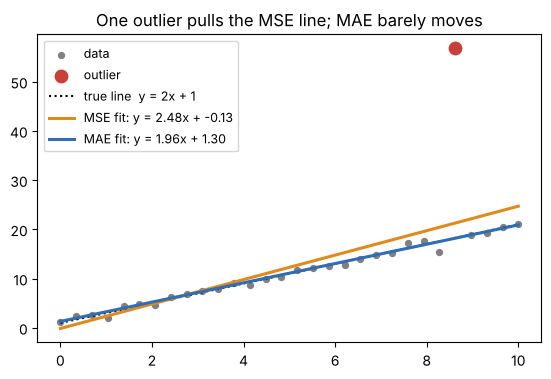

In [4]:
rng = np.random.default_rng(1)
x = np.linspace(0, 10, 30); y_line = 2 * x + 1 + rng.normal(0, 0.8, 30)
y_line[25] += 40                                   # one bad measurement
X_t, Y_t = torch.tensor(x, dtype=torch.float32), torch.tensor(y_line, dtype=torch.float32)

def fit(loss_fn, steps=3000, lr=0.01):
    w = torch.zeros(1, requires_grad=True); b = torch.zeros(1, requires_grad=True)
    opt = torch.optim.Adam([w, b], lr=0.1)
    for _ in range(steps):
        loss = loss_fn(w * X_t + b, Y_t); opt.zero_grad(); loss.backward(); opt.step()
    return w.item(), b.item()

fits = {"MSE": fit(F.mse_loss), "MAE": fit(F.l1_loss)}
plt.figure(figsize=(6.5, 4))
plt.scatter(x, y_line, s=18, c="grey", label="data"); plt.scatter(x[25], y_line[25], s=80, c="#c8403a", label="outlier")
plt.plot(x, 2 * x + 1, "k:", label="true line  y = 2x + 1")
for (name, (w, b)), col in zip(fits.items(), ["#e08a1e", "#2f6db5"]):
    plt.plot(x, w * x + b, color=col, lw=2.2, label=f"{name} fit: y = {w:.2f}x + {b:.2f}")
plt.legend(fontsize=9); plt.title("One outlier pulls the MSE line; MAE barely moves"); plt.show()

The single outlier drags the **MSE** line towards itself (its squared error is huge, so the optimiser works hard to reduce it). The **MAE** line stays close to the true line. So:
- **MSE** when large errors are especially bad and the data has no severe outliers;
- **MAE** when outliers are present and you want robustness.

MAE also reads naturally: "on average, off by ₹X".

MAE's catch: |x| has a **corner at 0** (not differentiable there), and its gradient is ±1 everywhere, so it doesn't shrink as you approach the answer. Optimisers cope, but behave differently than on smooth MSE. (Huber loss, MSE near 0 and MAE far away, is a popular compromise; it's not in the lecture.)

## 2 · Binary cross-entropy (BCE)

**BCE = −[ y·log(p) + (1 − y)·log(1 − p) ]**, where p is the predicted probability of class 1 (from a **sigmoid**).

In [5]:
bce = lambda y, p: -(y * np.log(p) + (1 - y) * np.log(1 - p))
print("actual y = 1:")
for p in [0.99, 0.90, 0.60, 0.10, 0.01]:
    print(f"   predicted p = {p:<4}  ->  loss = {bce(1, p):.3f}")

actual y = 1:
   predicted p = 0.99  ->  loss = 0.010
   predicted p = 0.9   ->  loss = 0.105
   predicted p = 0.6   ->  loss = 0.511
   predicted p = 0.1   ->  loss = 2.303
   predicted p = 0.01  ->  loss = 4.605


The lecture's table in numbers: 0.99 → **tiny** (0.010), 0.10 → **large** (2.303), 0.01 → **huge** (4.605). **BCE heavily punishes confident wrong predictions.**

### Why not MSE for classification? Compare the gradients
Suppose y = 1, but the network is confidently wrong: its logit is z = −5, so p = sigmoid(−5) ≈ 0.007. How hard does each loss push the logit to fix it?

In [6]:
for z0 in [-5.0, -2.0, 0.0, 2.0]:
    z = torch.tensor(z0, requires_grad=True)
    p = torch.sigmoid(z)
    (g_mse,) = torch.autograd.grad((p - 1.0) ** 2, z)
    z2 = torch.tensor(z0, requires_grad=True)
    (g_bce,) = torch.autograd.grad(F.binary_cross_entropy(torch.sigmoid(z2), torch.tensor(1.0)), z2)
    print(f"logit {z0:+.0f} (p = {p.item():.3f}):  gradient with MSE {g_mse.item():+.4f}   with BCE {g_bce.item():+.4f}")

logit -5 (p = 0.007):  gradient with MSE -0.0132   with BCE -0.9933
logit -2 (p = 0.119):  gradient with MSE -0.1850   with BCE -0.8808
logit +0 (p = 0.500):  gradient with MSE -0.2500   with BCE -0.5000
logit +2 (p = 0.881):  gradient with MSE -0.0250   with BCE -0.1192


**When the model is confidently wrong (logit −5), MSE's gradient almost vanishes (about −0.013), because the sigmoid is saturated, while BCE's stays strong (about −0.99).** With BCE + sigmoid, the gradient on the logit is simply **p − y**: the more wrong, the harder the push. This is the mathematical reason the lecture gives "classification is about probabilities and likelihood": BCE is the negative log-likelihood of the correct class.

## 3 · Categorical cross-entropy (CCE) with softmax

**CCE = −Σₖ yₖ·log(pₖ)**. With a one-hot label, only the correct class's term survives: **CCE = −log(p_correct)**.

In [7]:
p_digits = np.array([0.01, 0.02, 0.01, 0.03, 0.04, 0.02, 0.01, 0.82, 0.02, 0.02])   # lecture's softmax output
print("sums to", p_digits.sum().round(3), "-> predicted class:", p_digits.argmax())
one_hot_7 = np.eye(10)[7]
print("one-hot label for 7:", one_hot_7.astype(int))
print(f"CCE when p(7) = 0.82: {-np.sum(one_hot_7 * np.log(p_digits)):.3f}")
print(f"CCE when p(7) = 0.01: {-np.log(0.01):.3f}   <- confidently wrong, heavily punished")

sums to 1.0 -> predicted class: 7
one-hot label for 7: [0 0 0 0 0 0 0 1 0 0]
CCE when p(7) = 0.82: 0.198
CCE when p(7) = 0.01: 4.605   <- confidently wrong, heavily punished


### Categorical vs sparse categorical: same loss, different label format
- **Categorical CE** expects **one-hot** labels: 7 → [0,0,0,0,0,0,0,1,0,0].
- **Sparse categorical CE** expects the **integer** 7.

"Sparse" refers to how the **label** is written, **not** to the predictions. In PyTorch, `F.cross_entropy` / `nn.CrossEntropyLoss` accepts either.

In [8]:
logits = torch.randn(4, 10)                       # 4 images, 10 classes (raw scores, NOT softmax)
labels_int = torch.tensor([7, 2, 0, 9])           # "sparse" integer labels
labels_onehot = F.one_hot(labels_int, 10).float() # "categorical" one-hot labels
print("integer labels :", F.cross_entropy(logits, labels_int).item())
print("one-hot labels :", F.cross_entropy(logits, labels_onehot).item())
manual = -(labels_onehot * F.log_softmax(logits, dim=1)).sum(1).mean()
print("by hand (-sum y*log softmax):", manual.item())

integer labels : 2.5375328063964844
one-hot labels : 2.5375328063964844
by hand (-sum y*log softmax): 2.5375328063964844


All three numbers are identical: **same objective, different target representation**.

| Keras name | PyTorch | labels | output layer |
|---|---|---|---|
| `binary_crossentropy` | `nn.BCEWithLogitsLoss` (on logits) or `nn.BCELoss` (on sigmoid probabilities) | 0/1 | sigmoid |
| `categorical_crossentropy` | `nn.CrossEntropyLoss` with one-hot/probability targets | one-hot | softmax |
| `sparse_categorical_crossentropy` | `nn.CrossEntropyLoss` with integer targets | integers | softmax |
| `mse` / `mae` | `nn.MSELoss` / `nn.L1Loss` | numbers | linear |

### ⚠️ The most common PyTorch bug: softmax twice
`nn.CrossEntropyLoss` **already applies log-softmax** to the raw logits. If your model ends in `nn.Softmax` and you also use `CrossEntropyLoss`, you apply softmax twice:

In [9]:
logits = torch.tensor([[2.0, 0.0, -2.0]]); target = torch.tensor([0])
print("correct (logits in):          ", round(F.cross_entropy(logits, target).item(), 4))
print("bug (softmax, then the loss):  ", round(F.cross_entropy(F.softmax(logits, 1), target).item(), 4), "<- squashed, wrong, weak gradients")

correct (logits in):           0.1429
bug (softmax, then the loss):   0.6417 <- squashed, wrong, weak gradients


The same rule applies to binary problems: prefer `BCEWithLogitsLoss` on raw scores (numerically stable) over `Sigmoid` + `BCELoss`.

## 4 · Choosing a loss (the lecture's decision table, verified above)

| Problem | Loss | Output layer | Target format |
|---|---|---|---|
| regression | **MSE** | linear | continuous |
| regression with outliers | **MAE** | linear | continuous |
| binary classification | **binary CE** | sigmoid | 0 / 1 |
| multi-class | **categorical CE** | softmax | one-hot |
| multi-class | **sparse categorical CE** | softmax | integer |
| multi-label (several can be true) | binary CE on each output | one sigmoid per label | 0/1 vector |

**What each loss is "asking":**
- **MSE:** "how far is my number from the real number?"
- **MAE:** "how much numerical error, without over-weighting big errors?"
- **BCE:** "how well does my probability match the yes/no answer?"
- **CCE:** "how much probability did I give the correct class?"

## ✅ Check yourself
1. Actual (10, 20), predicted (12, 14). MSE? MAE? *(errors −2, 6 → MSE (4 + 36)/2 = 20, MAE (2 + 6)/2 = 4)*
2. Why is MSE outlier-sensitive? *(squared errors: one big error dominates the sum)*
3. y = 1, p = 0.5: BCE? *(−ln 0.5 = 0.693)*
4. Why does sigmoid + MSE learn slowly when confidently wrong? *(the sigmoid is saturated, so MSE's gradient ≈ 0; BCE's gradient on the logit is p − y)*
5. Sparse vs categorical CE: what's different? *(only the label format: integer vs one-hot)*
6. Your model ends with `nn.Softmax` and you use `nn.CrossEntropyLoss`. What's wrong? *(softmax applied twice: remove the Softmax layer and feed logits)*